# **Projeto: Previsão de Atrasos de Entrega (Olist)**

## Objetivo
O objetivo deste projeto é utilizar dados reais de e-commerce da Olist (cerca de 100 mil pedidos, de 2016 a 2018) para prever se um pedido vai chegar depois da data prometida ao cliente.

- **Variável alvo (target):** a coluna `atrasou`, que vale 1 se o pedido foi entregue após a data estimada e 0 se chegou no prazo ou antes.
- **Aplicação prática:** auxiliar as equipes de logística, atendimento e os próprios vendedores. Identificar pedidos com maior risco de atraso permite agir preventivamente (avisar o cliente, priorizar o envio ou ajustar a estimativa de prazo).
- **Momento da predição:** o modelo foi pensado para rodar no instante da compra. Por isso, tomei o cuidado de utilizar apenas informações que já existem até esse momento — variáveis que só aparecem depois (data de envio, data de entrega, avaliação do cliente) ficaram de fora para evitar vazamento de dados (*data leakage*).

## Sumário
1. Os Dados
2. Qualidade dos Dados e Criação do Target
3. Exploração dos Dados (EDA)
4. Preparação da Base para o Modelo
5. Modelagem
6. Avaliação do Modelo Final
7. Conclusão e Aplicação Prática

*Obs: utilizei o Claude (assistente de IA) como apoio durante o projeto para tirar dúvidas, revisar código e organizar a estrutura.*

## 1. Os Dados
O dataset é dividido em 9 tabelas (CSV). A tabela central é a `orders`, com uma linha por pedido, e as demais se conectam a ela por chaves como `order_id`, `customer_id`, `product_id` e `seller_id`. Carrego todas a seguir e faço os cruzamentos mantendo sempre a granularidade de uma linha por pedido.

In [7]:
# Bibliotecas usadas (dados, gráficos, modelos e métricas)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

# Lista os arquivos disponíveis no Kaggle
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv


In [8]:
# Pasta dos arquivos: a do Kaggle ou, rodando localmente, a pasta data/
caminho = "/kaggle/input/datasets/olistbr/brazilian-ecommerce/"
if not os.path.exists(caminho):
    caminho = "data/"

# Lendo cada CSV e guardando numa variável
orders    = pd.read_csv(caminho + "olist_orders_dataset.csv")
items     = pd.read_csv(caminho + "olist_order_items_dataset.csv")
payments  = pd.read_csv(caminho + "olist_order_payments_dataset.csv")
reviews   = pd.read_csv(caminho + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(caminho + "olist_customers_dataset.csv")
sellers   = pd.read_csv(caminho + "olist_sellers_dataset.csv")
products  = pd.read_csv(caminho + "olist_products_dataset.csv")
geoloc    = pd.read_csv(caminho + "olist_geolocation_dataset.csv")
traducao  = pd.read_csv(caminho + "product_category_name_translation.csv")

print("Tabelas carregadas!")

Tabelas carregadas!


In [9]:
# Tamanho da tabela de pedidos (linhas, colunas) e as primeiras linhas
print(orders.shape)
orders.head()

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
# Quantidade de pedidos em cada status
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Apenas os pedidos com status `delivered` (entregues) possuem a data real de entrega, então só neles consigo saber se houve atraso. Os outros 2.963 pedidos (enviados, cancelados, indisponíveis etc.) ficam de fora da base. Vale notar uma limitação aqui: pedidos `shipped`, que ainda estão em trânsito, já podem estar atrasados — ignorá-los pode fazer a taxa de atraso observada parecer um pouco menor do que a real.

## 2. Qualidade dos Dados e Criação do Target
Antes de criar a variável alvo (`atrasou`), verifico se existem valores nulos nas datas dos pedidos entregues.

### Tratamento: pedidos entregues sem data de entrega
Sem a data real de entrega não é possível determinar se o pedido atrasou, então começo checando os valores ausentes nessa amostra.

In [11]:
# Só os pedidos entregues
entregues = orders[orders["order_status"] == "delivered"]

# Quantos nulos há em cada coluna entre os entregues
entregues.isnull().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Apenas 8 pedidos entregues estão sem a data de entrega registrada. Também aparecem alguns nulos nas datas de aprovação e de postagem na transportadora, mas como essas colunas só existem após a compra e não entrarão no modelo, optei por remover apenas os 8 registros sem data de entrega.

### Criando o target
Um pedido é considerado atrasado quando a entrega real ocorre após a data estimada. Porém, no dataset a data estimada vem sempre cravada à meia-noite (`00:00:00`), enquanto a data de entrega inclui o horário exato. Se compararmos os timestamps diretamente, um pedido entregue às 15h do próprio dia prometido seria marcado como atrasado, mesmo tendo chegado no dia certo para o cliente.

Por isso, faço a comparação apenas pelo **dia** (`.dt.normalize()`). Abaixo também calculo a versão considerando a hora apenas para mostrar o tamanho dessa diferença.

In [12]:
# 1. Remover os 8 pedidos sem data de entrega
entregues = entregues.dropna(subset=["order_delivered_customer_date"]).copy()

# 2. Converter as colunas de data de texto para data de verdade
entregues["order_delivered_customer_date"] = pd.to_datetime(entregues["order_delivered_customer_date"])
entregues["order_estimated_delivery_date"] = pd.to_datetime(entregues["order_estimated_delivery_date"])

# 3. Conferir se a data estimada sempre vem à meia-noite (o resultado esperado é 1.0, ou seja, 100%)
est = entregues["order_estimated_delivery_date"]
print("Datas estimadas à meia-noite:", (est == est.dt.normalize()).mean())

# 4. Criar o target comparando só o DIA: 1 = entregue depois do dia estimado, 0 = no prazo
entregues["atrasou"] = (
    entregues["order_delivered_customer_date"].dt.normalize() > est.dt.normalize()
).astype(int)

# 5. Ver quantos atrasaram
print(entregues.shape)
print(entregues["atrasou"].value_counts())
print(entregues["atrasou"].value_counts(normalize=True) * 100)

Datas estimadas à meia-noite: 1.0
(96470, 9)
atrasou
0    89936
1     6534
Name: count, dtype: int64
atrasou
0    93.22691
1     6.77309
Name: proportion, dtype: float64


In [13]:
# Versão com hora, só para comparar: qualquer entrega depois de 00:00 do dia estimado vira "atraso"
entregues["atrasou_com_hora"] = (
    entregues["order_delivered_customer_date"] > entregues["order_estimated_delivery_date"]
).astype(int)

print(entregues["atrasou_com_hora"].value_counts())
print(entregues["atrasou_com_hora"].value_counts(normalize=True) * 100)

# Pedidos que a versão com hora marca como atrasados, mas que chegaram no dia prometido
print("Entregues no dia prometido (depois de 00:00):",
      ((entregues["atrasou_com_hora"] == 1) & (entregues["atrasou"] == 0)).sum())

atrasou_com_hora
0    88644
1     7826
Name: count, dtype: int64
atrasou_com_hora
0    91.887633
1     8.112367
Name: proportion, dtype: float64
Entregues no dia prometido (depois de 00:00): 1292


Comparando apenas o dia, temos 6.534 pedidos atrasados (6,77% dos 96.470 entregues). Se levássemos a hora em conta, esse número subiria para 7.826 (8,11%) — uma diferença de 1.292 pedidos que chegaram exatamente no dia prometido (após a meia-noite) e que seriam classificados incorretamente como atraso.

Sigo com o target oficial por dia (`atrasou`). Como os atrasos representam apenas 6,77% da base (classe bem desbalanceada), a acurácia comum não será uma boa métrica para avaliar os modelos mais adiante.

In [14]:
# Removendo as colunas auxiliares do target, para não confundir depois
entregues = entregues.drop(columns=["atrasou_com_hora"])

# Conferir o target oficial
print(entregues.shape)
print(entregues["atrasou"].value_counts())
print(entregues["atrasou"].value_counts(normalize=True) * 100)

(96470, 9)
atrasou
0    89936
1     6534
Name: count, dtype: int64
atrasou
0    93.22691
1     6.77309
Name: proportion, dtype: float64


## 3. Exploração dos Dados (EDA)
Nesta seção exploro as principais variáveis que podem influenciar o atraso de entrega, levantando hipóteses, criando novas features e limpando inconsistências pelo caminho.

### Hipótese 1: prazo prometido
A primeira ideia é que prazos prometidos muito curtos deixam pouca margem para imprevistos logísticos e devem concentrar mais atrasos. Como o prazo prometido (data estimada menos data da compra) já é informado no momento da compra, ele pode ser usado no modelo sem risco de vazamento.

In [15]:
# Converter a data de compra para data de verdade
entregues["order_purchase_timestamp"] = pd.to_datetime(entregues["order_purchase_timestamp"])

# Prazo prometido, em dias
entregues["prazo_prometido_dias"] = (
    entregues["order_estimated_delivery_date"] - entregues["order_purchase_timestamp"]
).dt.days

# Ver a distribuição do prazo
print(entregues["prazo_prometido_dias"].describe())

count    96470.000000
mean        23.372748
std          8.758421
min          2.000000
25%         18.000000
50%         23.000000
75%         28.000000
max        155.000000
Name: prazo_prometido_dias, dtype: float64


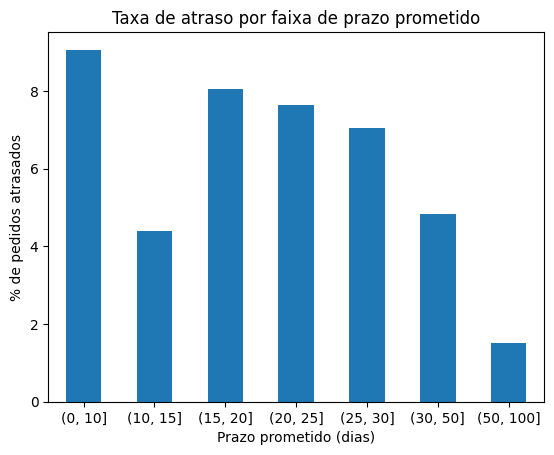

In [16]:
# Agrupando o prazo em faixas e calculando a taxa de atraso de cada uma
entregues["faixa_prazo"] = pd.cut(
    entregues["prazo_prometido_dias"],
    bins=[0, 10, 15, 20, 25, 30, 50, 100]
)

taxa = entregues.groupby("faixa_prazo", observed=True)["atrasou"].mean() * 100

taxa.plot(kind= "bar")
plt.title("Taxa de atraso por faixa de prazo prometido")
plt.ylabel("% de pedidos atrasados")
plt.xlabel("Prazo prometido (dias)")
plt.xticks(rotation = 0)
plt.show()

In [17]:
# Quantos pedidos há em cada faixa (para saber se a taxa é confiável)
print(entregues["faixa_prazo"].value_counts().sort_index())

faixa_prazo
(0, 10]       5176
(10, 15]     11450
(15, 20]     18680
(20, 25]     26437
(25, 30]     17674
(30, 50]     16189
(50, 100]      857
Name: count, dtype: int64


Os pedidos com prazo bem curto (até 10 dias) realmente atrasam mais que a média: cerca de 9% contra 6,8% geral, em uma faixa com bom volume (5.176 pedidos). Conforme o prazo aumenta para 30–50 dias (cerca de 5%) e 50–100 dias (cerca de 1,5%), a taxa de atraso cai bastante.

O comportamento só não é perfeitamente linear porque a faixa de 10 a 15 dias (cerca de 4,4%) atrasa menos que a de 15 a 20 dias (cerca de 8%). De todo modo, o prazo prometido mostra relação clara com o alvo e entra no modelo como `prazo_prometido_dias`.

### Hipótese 2: estado do cliente e do vendedor
A localização geográfica deve ter peso forte nos atrasos. Aqui cruzo o estado do cliente (`customer_state`) e o estado do vendedor (`seller_state`), além de criar a variável binária `mesmo_estado` para comparar entregas locais (dentro da mesma UF) com entregas interestaduais.

In [18]:
# Trazendo o estado do cliente para cada pedido (continua uma linha por pedido)
entregues = entregues.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

print(entregues.shape)
print(entregues["customer_state"].isnull().sum())

(96470, 12)
0


In [19]:
# Taxa de atraso por estado do cliente, com a quantidade de pedidos e de atrasados
taxa_estado = (
    entregues.groupby("customer_state")["atrasou"]
    .agg(pedidos="count", atrasados="sum", taxa_atraso="mean")
    .sort_values("taxa_atraso", ascending=False)
)
taxa_estado["taxa_atraso"] = (taxa_estado["taxa_atraso"] * 100).round(1)
taxa_estado = taxa_estado.rename(columns={
    "pedidos": "total_pedidos",
    "atrasados": "qtd_atrasados",
    "taxa_atraso": "taxa_atraso_%"
})
print(taxa_estado)

                total_pedidos  qtd_atrasados  taxa_atraso_%
customer_state                                             
AL                        397             85           21.4
MA                        717            125           17.4
SE                        335             51           15.2
PI                        476             66           13.9
CE                       1279            176           13.8
RR                         41              5           12.2
BA                       3256            396           12.2
RJ                      12350           1495           12.1
PA                        946            106           11.2
ES                       1995            214           10.7
PB                        517             54           10.4
TO                        274             27            9.9
MS                        701             68            9.7
PE                       1593            153            9.6
RN                        474           

In [20]:
# Estado do vendedor (do primeiro item do pedido) e a coluna mesmo_estado
vend_pedido = items.groupby("order_id")["seller_id"].first().reset_index()
vend_pedido = vend_pedido.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")

entregues = entregues.merge(vend_pedido[["order_id", "seller_state"]], on="order_id", how="left")

entregues["mesmo_estado"] = (entregues["customer_state"] == entregues["seller_state"]).astype(int)

print(entregues.shape)
print(entregues["seller_state"].isnull().sum())
print(entregues["seller_state"].value_counts().head(8))
print(entregues.groupby("mesmo_estado")["atrasou"].agg(["mean", "count"]))

(96470, 14)
0
seller_state
SP    68415
MG     7647
PR     7429
RJ     4185
SC     3551
RS     1949
DF      803
BA      549
Name: count, dtype: int64
                  mean  count
mesmo_estado                 
0             0.080477  61769
1             0.045042  34701


In [21]:
# Participação de cada estado no total de pedidos (por estado do vendedor)
part = (entregues["seller_state"].value_counts(normalize=True) * 100).round(1)
print(part.head(8).astype(str) + "%")

seller_state
SP    70.9%
MG     7.9%
PR     7.7%
RJ     4.3%
SC     3.7%
RS     2.0%
DF     0.8%
BA     0.6%
Name: proportion, dtype: object


Os vendedores são fortemente concentrados no Sudeste, com 70,9% dos pedidos saindo de SP. Olhando para o destino, as maiores taxas de atraso estão no Nordeste — AL (21,4%), MA (17,4%) e SE (15,2%) —, mas o RJ também se destaca negativamente: tem 12,1% de atraso em um volume alto (12.350 pedidos), mesmo sendo vizinho de SP. Além disso, compras dentro do mesmo estado atrasam quase a metade das interestaduais (4,5% contra 8,0%).

Isso mostra que a UF importa bastante e funciona em boa parte como um reflexo da distância física e da malha logística local. Vou manter `customer_state`, `seller_state` e `mesmo_estado` para os testes de modelagem.

### Construção: distância entre cliente e vendedor
Para ir além da sigla do estado, calculo a distância aproximada em quilômetros entre o CEP do vendedor e o CEP do cliente usando a fórmula de Haversine. Como a tabela `geoloc` possui várias coordenadas para um mesmo prefixo de CEP, primeiro agrupo tirando a média de latitude e longitude por prefixo para manter uma linha por pedido no cruzamento.

In [22]:
# Uma linha por prefixo de CEP (média das coordenadas)
geo = (
    geoloc.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .mean()
    .reset_index()
)

print("Linhas originais:", len(geoloc))
print("Linhas após agrupar:", len(geo))
print("Prefixos únicos:", geoloc["geolocation_zip_code_prefix"].nunique())

Linhas originais: 1000163
Linhas após agrupar: 19015
Prefixos únicos: 19015


Também trago o `seller_id` do primeiro item de cada pedido (mesmo critério usado para pegar a UF do vendedor) para buscar suas coordenadas. Antes de seguir, verifico em quantos pedidos existe mais de um vendedor para ter certeza de que essa simplificação não distorce a base.

In [23]:
# seller_id do primeiro item de cada pedido (mesmo critério do seller_state)
vend_id = items.groupby("order_id")["seller_id"].first().reset_index()

entregues = entregues.merge(vend_id, on="order_id", how="left")

print(entregues.shape)
print("seller_id nulos:", entregues["seller_id"].isnull().sum())
print("seller_id" in entregues.columns)

(96470, 15)
seller_id nulos: 0
True


In [24]:
# Quantos pedidos entregues têm itens de mais de um vendedor (checagem da simplificação de usar o primeiro)
vend_por_pedido = items.groupby("order_id")["seller_id"].nunique()
vend_por_pedido = vend_por_pedido[vend_por_pedido.index.isin(entregues["order_id"])]
mais_de_um = (vend_por_pedido > 1).sum()

print("Pedidos com mais de um vendedor:", mais_de_um, "de", len(vend_por_pedido))
print(f"Proporção: {mais_de_um / len(vend_por_pedido) * 100:.1f}%")

Pedidos com mais de um vendedor: 1275 de 96470
Proporção: 1.3%


Apenas 1.275 pedidos entregues (1,3% do total de 96.470) possuem itens de mais de um vendedor. Por ser uma fração mínima da base, considerar o vendedor do primeiro item é uma simplificação segura e evita duplicar linhas de pedidos.

In [25]:
# Prefixo de CEP e coordenadas do CLIENTE
cli = customers[["customer_id", "customer_zip_code_prefix"]].merge(
    geo, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left"
)
cli = cli.rename(columns={"geolocation_lat": "lat_cliente", "geolocation_lng": "lng_cliente"})

# Prefixo de CEP e coordenadas do VENDEDOR
ven = sellers[["seller_id", "seller_zip_code_prefix"]].merge(
    geo, left_on="seller_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left"
)
ven = ven.rename(columns={"geolocation_lat": "lat_vendedor", "geolocation_lng": "lng_vendedor"})

# Trazer para entregues
entregues = entregues.merge(
    cli[["customer_id", "lat_cliente", "lng_cliente"]], on="customer_id", how="left"
)
entregues = entregues.merge(
    ven[["seller_id", "lat_vendedor", "lng_vendedor"]], on="seller_id", how="left"
)

print(entregues.shape)
print(entregues[["lat_cliente", "lng_cliente", "lat_vendedor", "lng_vendedor"]].isnull().sum())

(96470, 19)
lat_cliente     264
lng_cliente     264
lat_vendedor    215
lng_vendedor    215
dtype: int64


In [26]:
# Fórmula de Haversine e distância em km entre vendedor e cliente
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # raio da Terra em km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

entregues["distancia_km"] = haversine(
    entregues["lat_vendedor"], entregues["lng_vendedor"],
    entregues["lat_cliente"], entregues["lng_cliente"]
)

print(entregues["distancia_km"].describe())

count    95992.000000
mean       600.757241
std        593.711747
min          0.000000
25%        185.933322
50%        433.872060
75%        798.548675
max       8677.911622
Name: distancia_km, dtype: float64


A distância média entre vendedor e cliente é de 601 km, enquanto a mediana fica em 434 km — diferença puxada por rotas muito longas. Porém, o valor máximo encontrado (8.678 km) ultrapassa qualquer distância possível dentro do território brasileiro, indicando erro de cadastro nas coordenadas de alguns CEPs. Além disso, restaram alguns pedidos com distância nula.

### Tratamento: coordenadas nulas
Com o cruzamento da geolocalização, 264 pedidos ficaram sem coordenadas do cliente e 215 sem as do vendedor (totalizando 478 pedidos distintos, cerca de 0,5% da base), pois seus prefixos de CEP não constam na tabela `geoloc`. Checo a taxa de atraso desse grupo antes de removê-los.

In [27]:
# Comparando a taxa de atraso dos pedidos sem distância com os demais, e removendo os sem distância
sem_dist = entregues[entregues["distancia_km"].isnull()]
com_dist = entregues[entregues["distancia_km"].notnull()]

print("Pedidos sem distância:", len(sem_dist))
print(f"Taxa de atraso nesses pedidos: {sem_dist['atrasou'].mean() * 100:.1f}%")
print(f"Taxa de atraso nos demais: {com_dist['atrasou'].mean() * 100:.1f}%")

entregues = entregues.dropna(subset=["distancia_km"]).copy()
print("Base após remoção:", entregues.shape)

Pedidos sem distância: 478
Taxa de atraso nesses pedidos: 9.2%
Taxa de atraso nos demais: 6.8%
Base após remoção: (95992, 20)


Esses 478 pedidos sem coordenadas têm uma taxa de atraso um pouco maior (9,2% contra 6,8% nos demais), mas como representam apenas 0,5% da base, optei por removê-los em vez de imputar distâncias artificiais. Seguimos com 95.992 pedidos.

### Tratamento: distâncias absurdas (Outliers)
Para limpar os erros de coordenadas identificados no `describe()`, filtro os pedidos com distância calculada acima de 4.500 km.

In [28]:
# Quantos pedidos passam de 4.500 km e exemplos, com os estados de origem e destino
print("Pedidos com distância > 4500 km:", (entregues["distancia_km"] > 4500).sum())
print(entregues[entregues["distancia_km"] > 4500][["customer_state", "seller_state", "distancia_km"]].head(10))

Pedidos com distância > 4500 km: 4
      customer_state seller_state  distancia_km
705               PR           SC   8677.911622
5470              PA           SP   5338.619521
69673             BA           SP   4791.614270
93924             PA           SP   5338.619521


Apareceram apenas 4 pedidos acima de 4.500 km, e todos são claramente erros de coordenada: um trajeto entre estados vizinhos (PR e SC) marcando 8.678 km, dois pedidos de SP para o PA com exatos 5.338 km (mesmo prefixo de CEP com coordenada incorreta) e um de SP para a BA com 4.792 km.

In [29]:
# Removendo os pedidos com distância impossível
antes = len(entregues)
entregues = entregues[entregues["distancia_km"] <= 4500].copy()
print("Removidos:", antes - len(entregues))
print("Base atual:", entregues.shape)

Removidos: 4
Base atual: (95988, 20)


In [30]:
# Teste extra: distância nos pedidos em que cliente e vendedor estão no mesmo estado
print(entregues[entregues["mesmo_estado"] == 1]["distancia_km"].describe())

count    34640.000000
mean       153.353052
std        146.229513
min          0.000000
25%         29.176182
50%         96.151095
75%        272.651726
max        926.862599
Name: distancia_km, dtype: float64


Removi esses 4 outliers da base. Como checagem adicional, conferi a distribuição das distâncias apenas para pedidos dentro do mesmo estado (`mesmo_estado == 1`): a média ficou em 153 km e o máximo em 927 km, valores totalmente coerentes com as dimensões dos estados brasileiros. Base limpa com **95.988 pedidos**.

### Hipótese 3: distância física
Com a variável `distancia_km` tratada, verifico se a taxa de atraso cresce de forma consistente conforme a distância entre vendedor e cliente aumenta.

            total_pedidos  qtd_atrasados taxa_atraso
faixa_dist                                          
até 100             17904            796        4.4%
100-300             13336            693        5.2%
300-600             31491           2122        6.7%
600-1000            17904           1270        7.1%
1000-1500            6589            584        8.9%
1500-2000            3155            347       11.0%
2000+                5609            677       12.1%


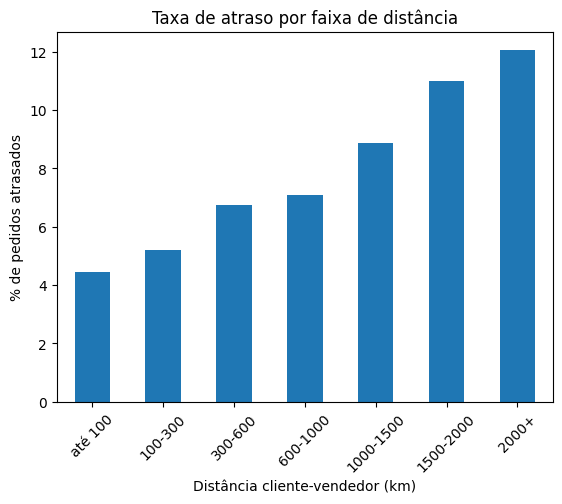

In [31]:
# Faixas de distância e taxa de atraso em cada uma (tabela e gráfico)
entregues["faixa_dist"] = pd.cut(
    entregues["distancia_km"],
    bins=[-1, 100, 300, 600, 1000, 1500, 2000, 4500],
    labels=["até 100", "100-300", "300-600", "600-1000", "1000-1500", "1500-2000", "2000+"]
)

dist = (
    entregues.groupby("faixa_dist", observed=True)["atrasou"]
    .agg(total_pedidos="count", qtd_atrasados="sum", taxa="mean")
)
dist["taxa_atraso"] = (dist["taxa"] * 100).round(1).astype(str) + "%"
print(dist[["total_pedidos", "qtd_atrasados", "taxa_atraso"]])

(dist["taxa"] * 100).plot(kind="bar")
plt.title("Taxa de atraso por faixa de distância")
plt.ylabel("% de pedidos atrasados")
plt.xlabel("Distância cliente-vendedor (km)")
plt.xticks(rotation=45)
plt.show()

A relação aqui é bem direta e monotônica: a taxa de atraso começa em 4,4% para entregas curtas (até 100 km), sobe para 6,7% na faixa de 300 a 600 km e chega a 12,1% nas rotas acima de 2.000 km — quase o triplo de risco da primeira faixa, e todas com bom volume de amostras. A variável `distancia_km` entra como uma das principais features do modelo.

### Hipótese 4: distância dentro das faixas de prazo
Como a Olist já costuma dar prazos maiores para lugares mais distantes, cruzo as duas variáveis em uma tabela dinâmica e um mapa de calor (*heatmap*) para verificar se a distância continua aumentando o risco de atraso mesmo quando comparamos pedidos com prazos prometidos semelhantes.

In [32]:
# Faixas de prazo (mais largas, para ter volume em cada célula)
entregues["faixa_prazo2"] = pd.cut(
    entregues["prazo_prometido_dias"],
    bins=[0, 15, 25, 35, 200],
    labels=["até 15d", "15-25d", "25-35d", "35d+"]
)

# Faixas de distância mais simples (4 grupos)
entregues["faixa_dist2"] = pd.cut(
    entregues["distancia_km"],
    bins=[-1, 300, 1000, 2000, 4500],
    labels=["até 300km", "300-1000km", "1000-2000km", "2000km+"]
)

# Taxa de atraso: linhas = prazo, colunas = distância
cruz = entregues.pivot_table(
    index="faixa_prazo2", columns="faixa_dist2",
    values="atrasou", aggfunc="mean", observed=True
) * 100

# Volume de pedidos em cada célula
vol = entregues.pivot_table(
    index="faixa_prazo2", columns="faixa_dist2",
    values="atrasou", aggfunc="count", observed=True
)

print("Taxa de atraso (%):")
print(cruz.round(1))
print("\nNúmero de pedidos:")
print(vol)

Taxa de atraso (%):
faixa_dist2   até 300km  300-1000km  1000-2000km  2000km+
faixa_prazo2                                             
até 15d             5.8         6.2          6.2     10.0
15-25d              4.3         8.4         15.0     21.8
25-35d              2.8         5.3          8.9     12.0
35d+                2.0         2.2          3.4      6.0

Número de pedidos:
faixa_dist2   até 300km  300-1000km  1000-2000km  2000km+
faixa_prazo2                                             
até 15d           13828        2650           81       20
15-25d            14021       27366         2430     1039
25-35d             2727       15945         5741     2908
35d+                664        3434         1492     1642


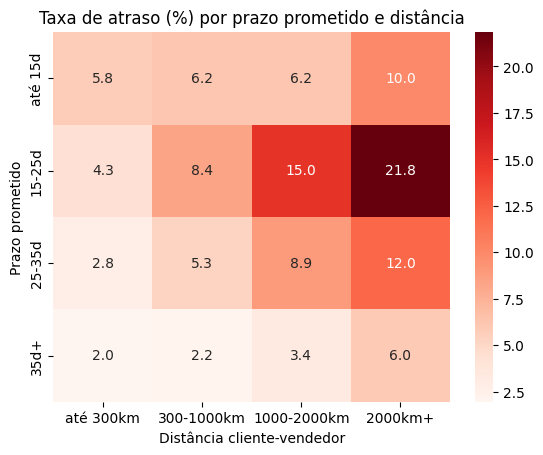

In [33]:
# Mapa de calor da taxa de atraso: linhas = prazo, colunas = distância
sns.heatmap(cruz, annot=True, fmt=".1f", cmap="Reds")
plt.title("Taxa de atraso (%) por prazo prometido e distância")
plt.xlabel("Distância cliente-vendedor")
plt.ylabel("Prazo prometido")
plt.show()

O mapa de calor deixa claro que o efeito da distância se mantém forte dentro de cada faixa de prazo. Olhando para os pedidos com prazo prometido entre 15 e 25 dias (onde está a maior parte do volume), a taxa de atraso salta de 4,3% em trajetos curtos (até 300 km) para 21,8% nos trajetos acima de 2.000 km. O mesmo padrão se repete na faixa de 25 a 35 dias (subindo de 2,8% para 12,0%).

Ou seja, o risco real mora na combinação entre um trajeto longo e um prazo pouco folgado — o que motiva a criação de uma variável combinada logo a seguir.

### Hipótese 5: folga do prazo (`dias_por_100km`)
Para capturar essa relação entre prazo e distância em uma única feature numérica, criei a coluna `dias_por_100km`, dividindo o prazo prometido pela distância em centenas de quilômetros (somando 1 no denominador para evitar divisão por zero em entregas muito próximas). Valores baixos indicam prazos apertados para o tamanho do trecho; valores altos indicam prazos mais folgados.

In [34]:
# Criando a feature de folga do prazo
entregues["dias_por_100km"] = entregues["prazo_prometido_dias"] / (entregues["distancia_km"] / 100 + 1)

print(entregues["dias_por_100km"].describe())

count    95988.000000
mean         5.396909
std          4.129375
min          0.372050
25%          2.753313
50%          4.198854
75%          6.667016
max         91.899243
Name: dias_por_100km, dtype: float64


                 total_pedidos  qtd_atrasados taxa_atraso
faixa_folga                                              
(0.371, 2.485]           19198           2066       10.8%
(2.485, 3.595]           19197           1485        7.7%
(3.595, 4.922]           19198           1355        7.1%
(4.922, 7.652]           19197            990        5.2%
(7.652, 91.899]          19198            593        3.1%


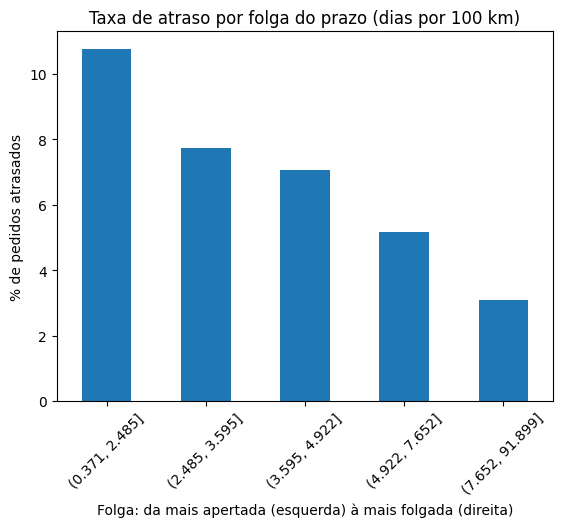

In [35]:
# Dividindo em 5 grupos de mesmo tamanho (do mais apertado ao mais folgado) e calculando a taxa de atraso
entregues["faixa_folga"] = pd.qcut(entregues["dias_por_100km"], q=5, duplicates="drop")

folga = (
    entregues.groupby("faixa_folga", observed=True)["atrasou"]
    .agg(total_pedidos="count", qtd_atrasados="sum", taxa="mean")
)
folga["taxa_atraso"] = (folga["taxa"] * 100).round(1).astype(str) + "%"
print(folga[["total_pedidos", "qtd_atrasados", "taxa_atraso"]])

(folga["taxa"] * 100).plot(kind="bar")
plt.title("Taxa de atraso por folga do prazo (dias por 100 km)")
plt.ylabel("% de pedidos atrasados")
plt.xlabel("Folga: da mais apertada (esquerda) à mais folgada (direita)")
plt.xticks(rotation=45)
plt.show()

Dividindo a base em 5 quintis de `dias_por_100km`, a separação dos atrasos fica muito nítida: os 20% de pedidos com prazo mais apertado para a distância têm 10,8% de atraso, e essa taxa cai degrau por degrau até chegar a 3,1% no quintil mais folgado. É um excelente preditor para entrar no modelo.

### Hipótese 6: sazonalidade
Avalio agora a evolução mensal da taxa de atraso para verificar se picos de demanda (como Black Friday e Natal) ou gargalos logísticos específicos afetam as entregas ao longo do tempo.

            pedidos   taxa
mes_compra                
2016-09           1  100.0
2016-10         265    0.8
2016-12           1    0.0
2017-01         750    2.9
2017-02        1653    3.0
2017-03        2536    4.5
2017-04        2288    6.5
2017-05        3527    2.9
2017-06        3114    3.1
2017-07        3853    2.8
2017-08        4170    2.9
2017-09        4125    4.4
2017-10        4450    4.2
2017-11        7250   12.4
2017-12        5482    7.4
2018-01        7036    5.7
2018-02        6516   14.1
2018-03        6969   18.9
2018-04        6763    4.5
2018-05        6716    6.6
2018-06        6068    1.2
2018-07        6132    3.3
2018-08        6323    6.2


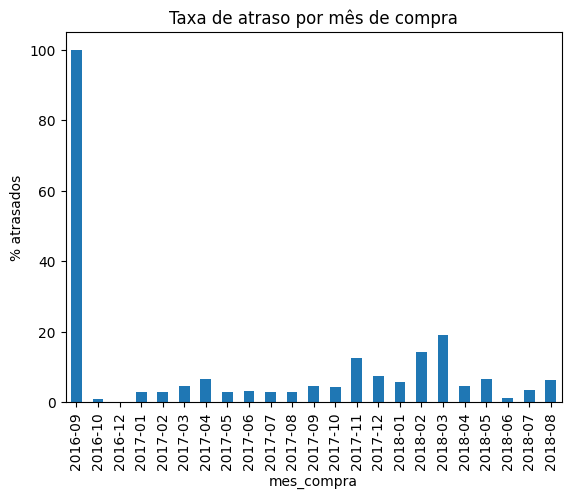

In [36]:
# Taxa de atraso por mês de compra (tabela e gráfico)
entregues["mes_compra"] = entregues["order_purchase_timestamp"].dt.to_period("M")

mes = entregues.groupby("mes_compra")["atrasou"].agg(pedidos="count", taxa="mean")
mes["taxa"] *= 100
print(mes.round(1))

mes["taxa"].plot(kind="bar")
plt.title("Taxa de atraso por mês de compra")
plt.ylabel("% atrasados")
plt.xticks(rotation=90)
plt.show()

Notam-se duas coisas importantes na série histórica: primeiro, o ano de 2016 quase não tem dados (setembro e dezembro têm apenas 1 pedido entregue cada), então não serve para análise. Segundo, a taxa de atraso varia muito conforme a época: fica comportada entre 2,8% e 6,5% durante quase todo o ano de 2017,mas dispara em novembro de 2017 (12,4%, puxado pela Black Friday) e atinge o pico em fevereiro (14,1%) e março de 2018 (18,9%).

Para checar se esses picos ocorreram apenas porque a plataforma prometeu prazos menores nesses meses, olho a média do prazo prometido mês a mês logo abaixo.

In [37]:
# Prazo médio prometido nos últimos 10 meses
entregues.groupby("mes_compra")["prazo_prometido_dias"].mean().round(1).tail(10)

mes_compra
2017-11    22.2
2017-12    27.3
2018-01    25.9
2018-02    24.2
2018-03    21.7
2018-04    23.3
2018-05    22.5
2018-06    27.4
2018-07    19.3
2018-08    14.8
Freq: M, Name: prazo_prometido_dias, dtype: float64

O prazo médio realmente foi mais curto em novembro/2017 (22,2 dias) e março/2018 (21,7 dias), mas foi mais alto em dezembro/2017 (27,3 dias), quando o sistema provavelmente ajustou as estimativas após a Black Friday. Ainda assim, o prazo não explica os picos sozinho: fevereiro/2018 teve um prazo médio alto (24,2 dias) e atrasou 14,1%, enquanto abril/2018 teve prazo de 23,3 dias e atrasou apenas 4,5% (reflexo de crises operacionais e greves dos Correios no início de 2018).

Essa mudança de comportamento ao longo do tempo reforça que a validação do modelo precisará respeitar a ordem cronológica (split temporal), além de justificarmos a inclusão do mês e dia da semana como features.

### Tratamento: remoção do ano de 2016
Como 2016 possui apenas 267 pedidos espalhados em três meses e com um hiato sem vendas em novembro, removo esses registros para manter a série temporal contínua a partir de janeiro de 2017.

In [38]:
# Mantendo só os pedidos a partir de 2017
antes = len(entregues)
entregues = entregues[entregues["order_purchase_timestamp"] >= "2017-01-01"].copy()
print("Removidos:", antes - len(entregues))
print("Base atual:", entregues.shape)

Removidos: 267
Base atual: (95721, 26)


Removidos os 267 pedidos de 2016, a base passa a cobrir de janeiro de 2017 a agosto de 2018 de forma contínua, totalizando 95.721 pedidos.

### Construção: peso, volume, preço e frete por pedido
Agora agrego as informações físicas e financeiras da tabela de itens e produtos para o nível de pedido: quantidade de itens (`qtd_itens`), peso total em gramas (`peso_total_g`), volume total em cm³ (`volume_total_cm3`), soma do preço (`preco_total`) e soma do frete (`frete_total`).

In [39]:
# Juntando itens e produtos, calculando o volume e resumindo tudo por pedido
prod = items.merge(
    products[["product_id", "product_weight_g", "product_length_cm",
              "product_height_cm", "product_width_cm"]],
    on="product_id", how="left"
)
prod["volume_cm3"] = prod["product_length_cm"] * prod["product_height_cm"] * prod["product_width_cm"]

por_pedido = prod.groupby("order_id").agg(
    qtd_itens=("order_item_id", "count"),
    peso_total_g=("product_weight_g", "sum"),
    volume_total_cm3=("volume_cm3", "sum"),
    preco_total=("price", "sum"),
    frete_total=("freight_value", "sum"),
).reset_index()

entregues = entregues.merge(por_pedido, on="order_id", how="left")
print(entregues.shape)
print(entregues[["peso_total_g", "volume_total_cm3"]].isnull().sum())

(95721, 31)
peso_total_g        0
volume_total_cm3    0
dtype: int64


In [40]:
# Conferindo zeros disfarçados de dado faltante e o resumo estatístico das colunas
print((entregues["peso_total_g"] == 0).sum())
print((entregues["volume_total_cm3"] == 0).sum())
print(entregues[["peso_total_g", "volume_total_cm3", "preco_total", "frete_total"]].describe())

22
16
        peso_total_g  volume_total_cm3   preco_total   frete_total
count   95721.000000      9.572100e+04  95721.000000  95721.000000
mean     2384.330095      1.735049e+04    137.043324     22.777772
std      4770.253647      3.020243e+04    209.359775     21.588507
min         0.000000      0.000000e+00      0.850000      0.000000
25%       300.000000      2.964000e+03     45.900000     13.830000
50%       750.000000      7.250000e+03     86.000000     17.160000
75%      2050.000000      1.987200e+04    149.900000     24.000000
max    184400.000000      1.476000e+06  13440.000000   1794.960000


Não ficaram valores nulos explícitos, mas o `describe()` mostra que existem 22 pedidos com peso zerado e 16 com volume zerado (produtos sem cadastro de dimensões que somaram zero). Também vemos a assimetria típica de dados de e-commerce, com alguns pedidos bem pesados (até 184 kg) ou de frete muito caro (até R$ 1.795) puxando a média para cima.

### Hipótese 7: peso do pedido
Cargas mais pesadas exigem manuseio específico e transporte menos ágil, então verifico se faixas maiores de peso concentram mais atrasos.

                    total_pedidos  qtd_atrasados taxa_atraso
faixa_peso                                                  
(-0.001, 250.0]             20388           1239        6.1%
(250.0, 500.0]              18211           1281        7.0%
(500.0, 1100.0]             18932           1183        6.2%
(1100.0, 2800.0]            19221           1349        7.0%
(2800.0, 184400.0]          18969           1434        7.6%


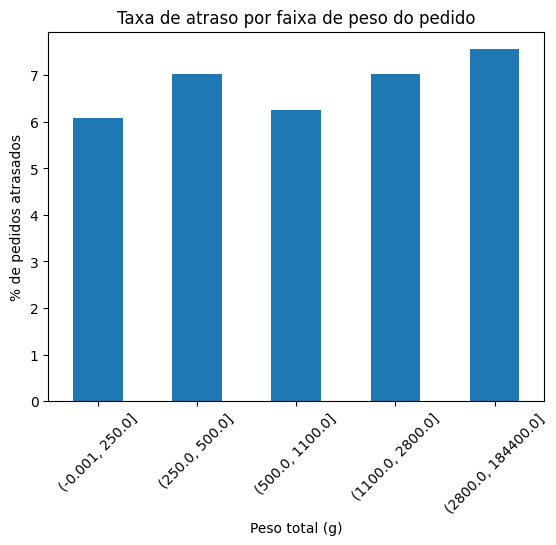

In [41]:
# Dividindo em 5 grupos de peso (do mais leve ao mais pesado) e calculando a taxa de atraso
entregues["faixa_peso"] = pd.qcut(entregues["peso_total_g"], q=5, duplicates="drop")

peso = (
    entregues.groupby("faixa_peso", observed=True)["atrasou"]
    .agg(total_pedidos="count", qtd_atrasados="sum", taxa="mean")
)
peso["taxa_atraso"] = (peso["taxa"] * 100).round(1).astype(str) + "%"
print(peso[["total_pedidos", "qtd_atrasados", "taxa_atraso"]])

(peso["taxa"] * 100).plot(kind="bar")
plt.title("Taxa de atraso por faixa de peso do pedido")
plt.ylabel("% de pedidos atrasados")
plt.xlabel("Peso total (g)")
plt.xticks(rotation=45)
plt.show()

A taxa de atraso oscila entre 6,1% na faixa mais leve (até 250g) e 7,6% na faixa mais pesada (acima de 2,8 kg). Existe uma leve tendência de alta nos produtos pesados, mas o efeito isolado do peso é bem mais modesto do que vimos na distância e na folga de prazo.

### Tratamento: peso e volume zerados
Como os 22 pedidos com peso ou volume igual a zero representam apenas 0,02% da base (dados ausentes de cadastro), faço a remoção direta dessas linhas.

In [42]:
# Removendo os pedidos com peso ou volume igual a 0
antes = len(entregues)
entregues = entregues[(entregues["peso_total_g"] > 0) & (entregues["volume_total_cm3"] > 0)].copy()
print("Removidos:", antes - len(entregues))
print("Base atual:", entregues.shape)

Removidos: 22
Base atual: (95699, 32)


Removidos os 22 registros inconsistentes, a base segue com 95.699 pedidos.

### Hipótese 8: frete relativo ao preço (`frete_pct_preco`)
Testo aqui se pedidos em que o frete representa uma fatia alta do valor do produto (`frete_total / preco_total`) atrasam mais.

                 total_pedidos  taxa
faixa_frete                         
(-0.001, 0.115]          19146   6.8
(0.115, 0.183]           19139   6.6
(0.183, 0.274]           19134   6.4
(0.274, 0.435]           19141   7.0
(0.435, 21.447]          19139   7.0


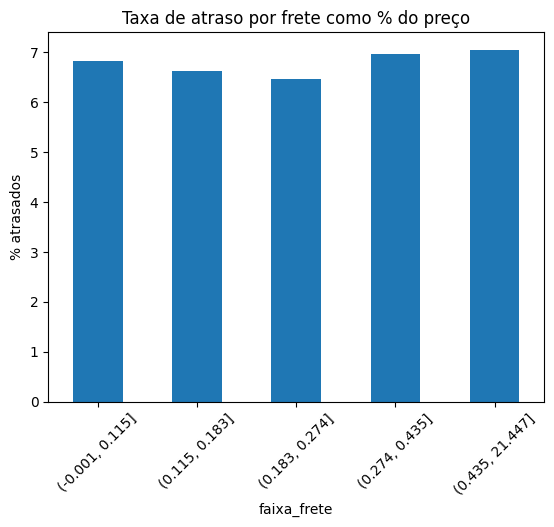

In [43]:
# Frete como fração do preço, em 5 grupos de mesmo tamanho, e taxa de atraso de cada um
entregues["frete_pct_preco"] = entregues["frete_total"] / entregues["preco_total"]
entregues["faixa_frete"] = pd.qcut(entregues["frete_pct_preco"], q=5, duplicates="drop")

fr = entregues.groupby("faixa_frete", observed=True)["atrasou"].agg(total_pedidos="count", taxa="mean")
fr["taxa"] *= 100
print(fr.round(1))

fr["taxa"].plot(kind="bar")
plt.title("Taxa de atraso por frete como % do preço")
plt.ylabel("% atrasados")
plt.xticks(rotation=45)
plt.show()

A taxa de atraso praticamente não muda entre os quintis dessa razão, ficando sempre entre 6,4% e 7,0%. O problema é que essa divisão mistura duas coisas diferentes: um frete proporcionalmente caro pode indicar tanto uma entrega distante quanto simplesmente um produto muito barato. Mantenho a coluna na base para teste nos modelos, mas avalio o valor bruto do frete separadamente a seguir.

### Hipótese 9: valor do frete em reais
Analisando agora o valor absoluto do frete (`frete_total`) dividido em 5 faixas, sem diluir pelo preço do produto.

In [44]:
# Frete em reais, em 5 grupos de mesmo tamanho, e taxa de atraso de cada um
entregues["faixa_frete_rs"] = pd.qcut(entregues["frete_total"], q=5, duplicates="drop")

fr2 = entregues.groupby("faixa_frete_rs", observed=True)["atrasou"].agg(total_pedidos="count", taxa="mean")
fr2["taxa"] *= 100
print(fr2.round(1))

                  total_pedidos  taxa
faixa_frete_rs                       
(-0.001, 12.81]           19160   4.4
(12.81, 15.63]            19159   6.0
(15.63, 18.58]            19131   7.6
(18.58, 27.37]            19118   7.7
(27.37, 1794.96]          19131   8.1


Sem dividir pelo preço, o sinal aparece claramente: a taxa de atraso sobe de 4,4% nos fretes mais baratos (até R$ 12,81) para 8,1% nos fretes acima de R$ 27,37 — quase o dobro. Boa parte disso reflete a própria distância e o peso do pacote, mas como o cálculo do frete na plataforma embute regras das transportadoras, `frete_total` entra como feature no modelo.

## 4. Preparação da Base para o Modelo

Com a exploração e limpeza concluídas, reúno as variáveis numéricas e categóricas construídas até aqui. O critério fundamental desta etapa é garantir que apenas dados conhecidos **no momento da compra** façam parte das features (`X`), descartando datas futuras (aprovação, postagem na transportadora e entrega real) para não causar vazamento de dados.

Conferindo todas as colunas presentes no DataFrame `entregues` antes da seleção:

In [45]:
# Colunas atuais, para decidir quais ficam no modelo
print(entregues.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'atrasou', 'prazo_prometido_dias', 'faixa_prazo', 'customer_state', 'seller_state', 'mesmo_estado', 'seller_id', 'lat_cliente', 'lng_cliente', 'lat_vendedor', 'lng_vendedor', 'distancia_km', 'faixa_dist', 'faixa_prazo2', 'faixa_dist2', 'dias_por_100km', 'faixa_folga', 'mes_compra', 'qtd_itens', 'peso_total_g', 'volume_total_cm3', 'preco_total', 'frete_total', 'faixa_peso', 'frete_pct_preco', 'faixa_frete', 'faixa_frete_rs']


### Seleção de Features e Montagem da Tabela Final
Extraio o mês (`mes`) e o dia da semana (`dia_semana`) do timestamp da compra e separo as listas de features numéricas e categóricas, descartando IDs e as colunas auxiliares de faixas que criei apenas para plotar os gráficos da EDA.

In [46]:
# Features de calendário a partir da data de compra
entregues["mes"] = entregues["order_purchase_timestamp"].dt.month
entregues["dia_semana"] = entregues["order_purchase_timestamp"].dt.dayofweek

features_num = [
    "prazo_prometido_dias", "distancia_km", "dias_por_100km", "mesmo_estado",
    "qtd_itens", "peso_total_g", "volume_total_cm3", "preco_total",
    "frete_total", "frete_pct_preco", "mes", "dia_semana",
]
features_cat = ["customer_state", "seller_state"]

base_modelo = entregues[
    ["order_purchase_timestamp", "atrasou"] + features_num + features_cat
].copy()

print(base_modelo.shape)
print(base_modelo.isnull().sum().sum(), "nulos no total")

(95699, 16)
0 nulos no total


A base final pronta para modelagem conta com **95.699 pedidos**, 14 features preditivas (12 numéricas e 2 categóricas), a coluna alvo `atrasou` e a data da compra (mantida apenas para fazer o corte temporal a seguir), sem nenhum valor nulo.

### Split Temporal de Treino e Teste
Diferente de problemas estáticos em que usamos um `train_test_split` aleatório, aqui vimos na EDA que a taxa de atraso sofre fortes oscilações ao longo dos meses. Sortear pedidos aleatoriamente misturaria passado e futuro, permitindo que o modelo aprendesse padrões de crises logísticas usando pedidos da mesma época que tentaria prever.

Por isso, ordeno os pedidos cronologicamente e uso os **80% mais antigos para treino** e os **20% mais recentes para teste**, simulando o cenário real de produção: treinar com o histórico passado para prever compras futuras.

In [47]:
# Dividindo pelo tempo: o corte fica no quantil 80% da data de compra
base_modelo = base_modelo.sort_values("order_purchase_timestamp")

corte = base_modelo["order_purchase_timestamp"].quantile(0.8)

treino = base_modelo[base_modelo["order_purchase_timestamp"] <= corte]
teste  = base_modelo[base_modelo["order_purchase_timestamp"] >  corte]

print("Corte em:", corte)
print("Treino:", treino.shape, "| atraso:", round(treino["atrasou"].mean() * 100, 1), "%")
print("Teste: ", teste.shape,  "| atraso:", round(teste["atrasou"].mean() * 100, 1), "%")
print("Período do treino:", treino["order_purchase_timestamp"].min(), "a", treino["order_purchase_timestamp"].max())
print("Período do teste: ", teste["order_purchase_timestamp"].min(),  "a", teste["order_purchase_timestamp"].max())

Corte em: 2018-05-27 14:59:10.600000
Treino: (76559, 16) | atraso: 7.6 %
Teste:  (19140, 16) | atraso: 3.5 %
Período do treino: 2017-01-05 11:56:06 a 2018-05-27 14:58:45
Período do teste:  2018-05-27 14:59:49 a 2018-08-29 15:00:37


O corte temporal ficou em **27 de maio de 2018**:
- **Treino:** 76.559 pedidos (jan/2017 a mai/2018), com taxa de atraso de **7,6%**.
- **Teste:** 19.140 pedidos (fim de mai/2018 a ago/2018), com taxa de atraso de **3,5%**.

Vale notar um ponto importante: a taxa de atraso no período de teste caiu para menos da metade da taxa do treino, já que os picos críticos do final de 2017 e início de 2018 ficaram todos no passado (treino), e a operação normalizou no meio de 2018. Isso torna a validação no conjunto de teste um desafio bem realista de mudança de regime (*concept drift*).

## 5. Modelagem
Para avaliar os modelos neste cenário desbalanceado (apenas 3,5% de positivos no teste), a acurácia tradicional não serve — um modelo que previsse "zero atraso" para tudo acertaria 96,5% dos casos sem ter utilidade nenhuma. Utilizo duas métricas baseadas no ranking de probabilidades geradas pelo modelo:

- **PR-AUC (Average Precision):** métrica principal do projeto. Avalia o equilíbrio entre *Precision* (dos pedidos que o modelo apontou risco, quantos realmente atrasaram) e *Recall* (do total de atrasos reais, quantos o modelo capturou) ao longo de todos os pontos de corte. O baseline de um chute aleatório para PR-AUC é a própria taxa de positivos do teste (**0,035**).
- **ROC-AUC:** mede a capacidade global de ordenação do modelo — a probabilidade de ele atribuir um score de risco maior para um pedido que atrasou do que para um pedido entregue no prazo (onde **0,500** equivale a um sorteio aleatório e **1,000** é uma separação perfeita).

### Modelo 1: Regressão Logística (Baseline)
Começo com uma Regressão Logística utilizando as variáveis numéricas padronizadas (`StandardScaler` ajustado apenas no treino) e `class_weight="balanced"` para compensar a raridade dos atrasos. O objetivo é estabelecer um baseline linear simples para comparar com os modelos de árvores depois.

In [48]:
# Guarda as notas de cada modelo, para montar a tabela resumo no fim
resultados = {}

# Colunas numéricas desta regressão (tudo, menos data, target e estados)
features_num = [c for c in treino.columns if c not in ["order_purchase_timestamp", "atrasou", "customer_state", "seller_state"]]

# Separando as variáveis (X) e o que quero prever (y), no treino e no teste
X_treino = treino[features_num]
X_teste = teste[features_num]
y_treino = treino["atrasou"]
y_teste = teste["atrasou"]

# Colocando as variáveis na mesma escala; a escala é aprendida só no treino
escala = StandardScaler()
X_treino_e = escala.fit_transform(X_treino)
X_teste_e = escala.transform(X_teste)

# Treinando; class_weight="balanced" dá mais peso aos atrasos, que são raros
modelo = LogisticRegression(class_weight="balanced", max_iter=1000)
modelo.fit(X_treino_e, y_treino)

# Nota de risco (probabilidade de atraso) de cada pedido do teste
prob = modelo.predict_proba(X_teste_e)[:, 1]

# Notas do modelo; a PR-AUC de um chute é a própria taxa de atraso do teste
pr = average_precision_score(y_teste, prob)
roc = roc_auc_score(y_teste, prob)
resultados["Chute aleatório"] = (y_teste.mean(), 0.5)
resultados["Regressão logística (referência)"] = (pr, roc)

print("PR-AUC:", round(pr, 3))
print("ROC-AUC:", round(roc, 3))
print("PR-AUC de um chute aleatório:", round(y_teste.mean(), 3))

PR-AUC: 0.069
ROC-AUC: 0.678
PR-AUC de um chute aleatório: 0.035


A Regressão Logística obteve **PR-AUC de 0,069** (praticamente o dobro do baseline aleatório de 0,035) e **ROC-AUC de 0,678**. É um ponto de partida coerente: mostra que as variáveis de prazo, distância e frete já carregam sinal preditivo mesmo em uma combinação puramente linear.

### Modelo 2: LightGBM
Parto agora para o LightGBM, um algoritmo de *Gradient Boosting* baseado em árvores de decisão que consegue capturar relações não-lineares, interações entre variáveis (como distância x prazo) e lidar nativamente com as colunas categóricas de estado (`customer_state` e `seller_state`).

In [49]:
# Lista de variáveis do LightGBM: as numéricas mais os dois estados
cat = ["customer_state", "seller_state"]
cols = features_num + cat

# Os estados viram tipo "category"; no teste uso as mesmas categorias do treino
X_treino2 = treino[cols].copy()
X_teste2 = teste[cols].copy()
for c in cat:
    X_treino2[c] = X_treino2[c].astype("category")
    X_teste2[c] = pd.Categorical(X_teste2[c], categories=X_treino2[c].cat.categories)

# Treinando: 300 árvores, passo de aprendizado 0.05 e até 31 folhas por árvore (valores de partida)
modelo2 = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
modelo2.fit(X_treino2, y_treino)

# Nota de risco de cada pedido do teste
prob2 = modelo2.predict_proba(X_teste2)[:, 1]

pr2 = average_precision_score(y_teste, prob2)
roc2 = roc_auc_score(y_teste, prob2)
resultados["LightGBM"] = (pr2, roc2)

print("PR-AUC:", round(pr2, 3))
print("ROC-AUC:", round(roc2, 3))

PR-AUC: 0.067
ROC-AUC: 0.702


O LightGBM alcançou **ROC-AUC de 0,702** (uma melhora clara de ordenação frente aos 0,678 da Regressão Logística), mas a **PR-AUC ficou em 0,067**, praticamente empatada com o modelo linear (0,069). O ganho limitado ao trocar um modelo linear simples por um ensemble de árvores sugere que o gargalo não está na capacidade do algoritmo, mas na mudança de padrão entre o período de treino e o de teste.

### Teste de Hipótese na Modelagem: impacto da variável `mes` e complexidade das árvores
Na exploração vimos que fevereiro e março de 2018 tiveram picos atípicos de atraso no treino. Como o conjunto de teste compreende apenas maio a agosto de 2018, levantei a hipótese de que a variável `mes` ou árvores muito profundas (`num_leaves=31`) pudessem estar causando *overfitting* nos meses passados. Abaixo testo duas variações sem a coluna `mes`: uma mantendo os hiperparâmetros e outra com árvores bem mais rasas e regularizadas (`num_leaves=8`, `min_child_samples=100`).

In [50]:
# Mesmas variáveis, sem o mês
cols_sem_mes = [c for c in cols if c != "mes"]

# Mesmo LightGBM de antes, treinado sem o mês
modelo3 = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
modelo3.fit(X_treino2[cols_sem_mes], y_treino)
prob3 = modelo3.predict_proba(X_teste2[cols_sem_mes])[:, 1]

pr3 = average_precision_score(y_teste, prob3)
roc3 = roc_auc_score(y_teste, prob3)
resultados["LightGBM sem o mês"] = (pr3, roc3)

print("Sem mês | PR-AUC:", round(pr3, 3))
print("Sem mês | ROC-AUC:", round(roc3, 3))

Sem mês | PR-AUC: 0.055
Sem mês | ROC-AUC: 0.606


In [51]:
# Versão simples: menos árvores, folhas menores e mínimo de 100 pedidos por folha (evita ajuste excessivo)
modelo4 = lgb.LGBMClassifier(
    n_estimators=150, learning_rate=0.03, num_leaves=8, min_child_samples=100,
    class_weight="balanced", random_state=42, verbose=-1
)
modelo4.fit(X_treino2[cols_sem_mes], y_treino)
prob4 = modelo4.predict_proba(X_teste2[cols_sem_mes])[:, 1]

pr4 = average_precision_score(y_teste, prob4)
roc4 = roc_auc_score(y_teste, prob4)
resultados["LightGBM simples, sem o mês"] = (pr4, roc4)

print("Simples | PR-AUC:", round(pr4, 3))
print("Simples | ROC-AUC:", round(roc4, 3))

Simples | PR-AUC: 0.061
Simples | ROC-AUC: 0.643


Ao contrário da suspeita inicial, remover a coluna `mes` derrubou o desempenho do modelo: a ROC-AUC caiu de 0,702 para **0,606** (e a PR-AUC caiu de 0,067 para **0,055**). Restringir a profundidade das árvores no `modelo4` recuperou parte da generalização (subindo a ROC-AUC para **0,643** e a PR-AUC para **0,061**), mas ainda ficou abaixo do modelo com o mês. Por isso, mantenho `mes` no conjunto de features.

### Hipótese 10 (Feature Engineering): histórico de atrasos do vendedor
Como trocar de algoritmo não aumentou a PR-AUC, voltei aos dados para construir uma informação nova que capturasse o comportamento individual de cada lojista: a taxa histórica de atrasos do vendedor (`vend_hist_taxa`) e o volume de entregas anteriores dele (`vend_hist_n`).

Para evitar vazamento de dados do futuro (*data leakage*), o cálculo para cada pedido considera **apenas os pedidos anteriores daquele vendedor que já haviam sido efetivamente entregues antes do instante da nova compra** (usando busca binária `np.searchsorted` sobre as datas de entrega). Além disso, apliquei suavização bayesiana (*target encoding smoothing* com peso `k = 20`) puxando a taxa de vendedores iniciantes para a média geral do treino, evitando que 1 atraso na primeira venda gerasse uma taxa distorcida de 100%.

In [52]:
# Para cada pedido: taxa de atraso do vendedor usando só entregas que já eram conhecidas na hora da compra
h = entregues[["order_id", "seller_id", "order_purchase_timestamp",
               "order_delivered_customer_date", "atrasou"]].copy()
h["order_delivered_customer_date"] = pd.to_datetime(h["order_delivered_customer_date"])

media_geral = entregues.loc[
    entregues["order_purchase_timestamp"] <= corte, "atrasou"
].mean()
k = 20  # força da suavização: equivale a 20 pedidos "médios" no histórico

hist_taxa = pd.Series(index=h.index, dtype=float)
hist_n = pd.Series(index=h.index, dtype=float)

for vend, g in h.groupby("seller_id"):
    # resultados do vendedor, ordenados pela data em que ficaram conhecidos (entrega)
    res = g.sort_values("order_delivered_customer_date")
    datas_res = res["order_delivered_customer_date"].values
    cum_atr = np.cumsum(res["atrasou"].values)

    # para cada pedido: quantos resultados já eram conhecidos na data da compra?
    compras = g["order_purchase_timestamp"].values
    pos = np.searchsorted(datas_res, compras, side="left")  # nº de entregas antes da compra
    n = pos
    atr = np.where(pos > 0, cum_atr[np.maximum(pos - 1, 0)], 0)

    hist_n.loc[g.index] = n
    hist_taxa.loc[g.index] = (atr + k * media_geral) / (n + k)

entregues["vend_hist_taxa"] = hist_taxa
entregues["vend_hist_n"] = hist_n

print(entregues[["vend_hist_taxa", "vend_hist_n"]].describe())

       vend_hist_taxa   vend_hist_n
count    95699.000000  95699.000000
mean         0.058931    168.768242
std          0.030998    282.346411
min          0.006729      0.000000
25%          0.037153     12.000000
50%          0.054309     51.000000
75%          0.072412    180.000000
max          0.361856   1783.000000


In [53]:
# Lista de variáveis agora com o histórico do vendedor
features_num_orig = [
    "prazo_prometido_dias", "distancia_km", "dias_por_100km", "mesmo_estado",
    "qtd_itens", "peso_total_g", "volume_total_cm3", "preco_total",
    "frete_total", "frete_pct_preco", "mes", "dia_semana",
]
features_cat = ["customer_state", "seller_state"]

# Refazendo a tabela do modelo com as duas colunas novas, na mesma ordem de datas
base_modelo = entregues[
    ["order_purchase_timestamp", "atrasou"] + features_num_orig
    + ["vend_hist_taxa", "vend_hist_n"] + features_cat
].copy().sort_values("order_purchase_timestamp")

# Mesma divisão de treino e teste (mesmo corte de data)
treino = base_modelo[base_modelo["order_purchase_timestamp"] <= corte]
teste  = base_modelo[base_modelo["order_purchase_timestamp"] >  corte]

# Variáveis do modelo e conversão dos estados para "category"
cols = features_num_orig + ["vend_hist_taxa", "vend_hist_n"] + features_cat
X_treino2 = treino[cols].copy()
X_teste2 = teste[cols].copy()
for c in features_cat:
    X_treino2[c] = X_treino2[c].astype("category")
    X_teste2[c] = pd.Categorical(X_teste2[c], categories=X_treino2[c].cat.categories)

y_treino, y_teste = treino["atrasou"], teste["atrasou"]

# Mesmo LightGBM do modelo 2, agora com o histórico do vendedor (comparação justa)
modelo5 = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
modelo5.fit(X_treino2, y_treino)
prob5 = modelo5.predict_proba(X_teste2)[:, 1]

pr5 = average_precision_score(y_teste, prob5)
roc5 = roc_auc_score(y_teste, prob5)
resultados["LightGBM + histórico do vendedor"] = (pr5, roc5)

print("Com histórico do vendedor | PR-AUC:", round(pr5, 3))
print("Com histórico do vendedor | ROC-AUC:", round(roc5, 3))

Com histórico do vendedor | PR-AUC: 0.065
Com histórico do vendedor | ROC-AUC: 0.669


As features históricas ficaram bem distribuídas (mediana de 51 entregas anteriores por vendedor e taxas suavizadas variando de 0,7% a 36,2%), mas ao retreinar o LightGBM (`modelo5`), o desempenho no teste caiu para **PR-AUC de 0,065** e **ROC-AUC de 0,669**.

Isso indica que a localização do vendedor, a distância e o prazo já capturavam a maior parte do risco estrutural, ou que os atrasos na Olist dependem muito mais da malha dos Correios na época da entrega do que de uma "culpa recorrente" do vendedor.

### Teste de Estabilidade: removendo as colunas de estado (`customer_state` e `seller_state`)
Como vimos na EDA que estados com grande volume (como RJ e BA) sofreram crises logísticas agudas no treino que se normalizaram depois, testei treinar o LightGBM (`modelo6`) mantendo todas as variáveis numéricas e de histórico do vendedor, mas **removendo as siglas dos estados**, forçando o algoritmo a se guiar pela distância física (`distancia_km`), pela folga (`dias_por_100km`) e pelo indicador `mesmo_estado`.

In [54]:
# Mesmas variáveis, sem os dois estados
cols_sem_estado = [c for c in cols if c not in ["customer_state", "seller_state"]]

# Mesmo LightGBM, treinado sem os estados
modelo6 = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
modelo6.fit(X_treino2[cols_sem_estado], y_treino)
prob6 = modelo6.predict_proba(X_teste2[cols_sem_estado])[:, 1]

pr6 = average_precision_score(y_teste, prob6)
roc6 = roc_auc_score(y_teste, prob6)
resultados["LightGBM sem os estados (final)"] = (pr6, roc6)

print("Sem estados | PR-AUC:", round(pr6, 3))
print("Sem estados | ROC-AUC:", round(roc6, 3))

Sem estados | PR-AUC: 0.071
Sem estados | ROC-AUC: 0.699


Sem as colunas categóricas de estado, o LightGBM atingiu o **melhor resultado de PR-AUC entre todos os experimentos (0,071 — mais que o dobro do chute aleatório)** e recuperou a **ROC-AUC para 0,699**. Isso confirma que usar a sigla da UF diretamente fazia o modelo penalizar certos estados no período de teste com base em crises regionais que já tinham passado no treino (como veremos em detalhe na análise de erros da Seção 6).

### Comparação Geral dos Modelos
Reunindo as métricas de todas as versões testadas lado a lado:

In [55]:
# Tabela resumo montada a partir das notas guardadas em "resultados"
resumo = pd.DataFrame(
    [(nome, round(pr, 3), round(roc, 3)) for nome, (pr, roc) in resultados.items()],
    columns=["Modelo", "PR-AUC", "ROC-AUC"]
)
print(resumo.to_string(index=False))

                          Modelo  PR-AUC  ROC-AUC
                 Chute aleatório   0.035    0.500
Regressão logística (referência)   0.069    0.678
                        LightGBM   0.067    0.702
              LightGBM sem o mês   0.055    0.606
     LightGBM simples, sem o mês   0.061    0.643
LightGBM + histórico do vendedor   0.065    0.669
 LightGBM sem os estados (final)   0.071    0.699


Todos os modelos superaram com folga o baseline aleatório ( dobrando a PR-AUC de 0,035 para a faixa de 0,065–0,071 e levando a ROC-AUC para ~0,70). O experimento mais revelador foi perceber que a Regressão Logística (0,069) já chegava muito perto do LightGBM completo, e que **retirar as variáveis de estado (`modelo6`)** foi o ajuste que destravou a maior precisão média no conjunto de teste (PR-AUC 0,071).

### Escolha do Modelo Final
Escolho como modelo final o **LightGBM sem as colunas de estado (`modelo6`)**, pois ele entregou a maior PR-AUC (0,071) combinada com excelente capacidade de ordenação (ROC-AUC 0,699), além de ser conceitualmente mais robusto contra variações regionais pontuais por se apoiar na distância física e na folga do prazo.

In [56]:
# Definindo o modelo final (LightGBM sem as colunas de estado) e a nota de risco dele no teste
modelo_final = modelo6
prob_final = prob6

print("Modelo final: LightGBM sem as colunas de estado")
print("PR-AUC:", round(average_precision_score(y_teste, prob_final), 3))
print("ROC-AUC:", round(roc_auc_score(y_teste, prob_final), 3))

Modelo final: LightGBM sem as colunas de estado
PR-AUC: 0.071
ROC-AUC: 0.699


## 6. Avaliação do Modelo Final
As métricas globais (PR-AUC e ROC-AUC) resumem a qualidade matemática do ranking, mas não respondem diretamente à pergunta de negócio: **se a operação logística usar esse modelo para priorizar uma fração dos pedidos, quantos atrasos conseguimos antecipar?**

Abaixo avalio o ganho prático por faixas de priorização (Curva de Ganho / *Lift*), a importância das features e onde o modelo mais acerta ou erra.

### Ganho Prático na Operação (Tabela de Lift e Curva de Ganho)
Na prática, a equipe de logística ou atendimento não consegue intervir manualmente em 100% das compras. A estratégia realista é ordenar os pedidos pelo score de risco gerado pelo modelo na hora da compra e atuar na fatia mais crítica (os top 5%, 10%, 20% ou 30% de maior risco). Abaixo comparo quantos atrasos reais capturamos em cada faixa contra o que pegaríamos escolhendo pedidos por sorteio.

In [57]:
# Ordenando os pedidos do teste do maior para o menor risco e contando os atrasos pegos em cada fatia
res = pd.DataFrame({"atrasou": y_teste.values, "risco": prob_final})
res = res.sort_values("risco", ascending=False).reset_index(drop=True)

total_atrasos = res["atrasou"].sum()
linhas = []
for pct in [5, 10, 20, 30]:
    n = int(len(res) * pct / 100)
    pegos = res["atrasou"].iloc[:n].sum()
    linhas.append({
        "% dos pedidos marcados": pct,
        "atrasos pegos": pegos,
        "% dos atrasos pegos": round(pegos / total_atrasos * 100, 1),
        "% da taxa de atraso no grupo": round(pegos / n * 100, 1),
        "vezes melhor que sortear": round((pegos / total_atrasos) / (pct / 100), 2),
    })

print(f"Total de atrasos no teste: {total_atrasos} de {len(res)} pedidos")
print(pd.DataFrame(linhas).to_string(index=False))

Total de atrasos no teste: 665 de 19140 pedidos
 % dos pedidos marcados  atrasos pegos  % dos atrasos pegos  % da taxa de atraso no grupo  vezes melhor que sortear
                      5             82                 12.3                           8.6                      2.47
                     10            137                 20.6                           7.2                      2.06
                     20            259                 38.9                           6.8                      1.95
                     30            376                 56.5                           6.5                      1.88


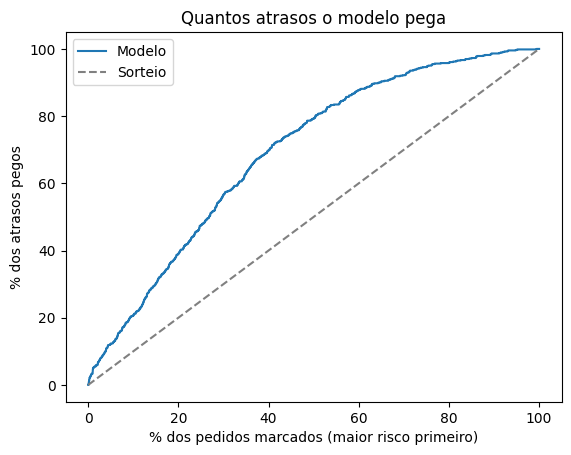

In [58]:
# Curva de ganho: % de atrasos pegos conforme mais pedidos são marcados (a linha tracejada é o sorteio)
x = np.arange(1, len(res) + 1) / len(res) * 100
y = res["atrasou"].cumsum().values / total_atrasos * 100

plt.plot(x, y, label="Modelo")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Sorteio")
plt.xlabel("% dos pedidos marcados (maior risco primeiro)")
plt.ylabel("% dos atrasos pegos")
plt.title("Quantos atrasos o modelo pega")
plt.legend()
plt.show()

Analisando os resultados práticos nos 19.140 pedidos do período de teste (onde ocorreram 665 atrasos reais):
- **Top 5% de maior risco:** concentra uma taxa de atraso de **8,6%** (quase **2,5x maior** que a média do teste, de 3,5%), capturando **12,3%** de todos os atrasos (82 de 665).
- **Top 10% de maior risco:** captura **20,6% de todos os atrasos reais** (137 de 665), com uma taxa de atraso de **7,2%** no grupo (**2,06x melhor que um sorteio**).
- **Top 20% e Top 30%:** ao monitorar os 20% mais críticos, antecipamos **38,9%** dos problemas (259 atrasos); subindo a régua para os 30% de maior risco, capturamos **56,5% de todos os atrasos da plataforma** (376 de 665).

**Tradução para o negócio:** o modelo agrega bastante valor como ferramenta de priorização, dobrando a eficiência da equipe ao focar nos 10% a 20% de pedidos mais arriscados. Por outro lado, como o atraso é um evento raro (3,5% no teste), mesmo dentro do top 10% cerca de **92,8% dos pedidos ainda chegam no prazo**, e atuar apenas nos 10% deixa **79,4% dos atrasos de fora**. Ou seja, o score deve acionar medidas preventivas de **baixo custo e escaláveis** (como folga automática no prazo exibido ou alerta de priorização para o seller), e não intervenções manuais caras pedido a pedido.

### Importância das Variáveis (Feature Importance)
Verificando quais variáveis mais contribuíram para a redução do erro (ganho de informação / *gain*) nas divisões das árvores do modelo final:

mes                     20.2
dias_por_100km          16.1
prazo_prometido_dias    11.7
vend_hist_taxa           8.2
vend_hist_n              7.4
frete_total              5.6
distancia_km             5.2
volume_total_cm3         5.0
mesmo_estado             4.7
peso_total_g             4.7
preco_total              4.7
frete_pct_preco          3.8
dia_semana               1.8
qtd_itens                0.8
dtype: float64


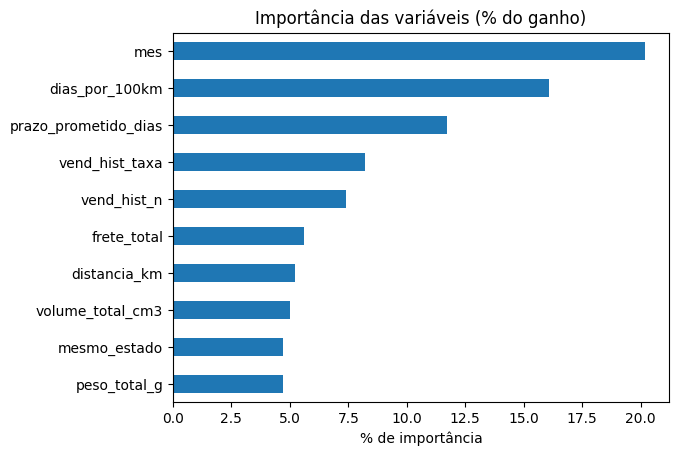

In [59]:
# Importância de cada coluna (% do ganho) em tabela e gráfico
imp = pd.Series(modelo_final.booster_.feature_importance(importance_type="gain"), index=cols_sem_estado)
imp = (imp / imp.sum() * 100).sort_values(ascending=False).round(1)
print(imp)

imp.head(10).sort_values().plot(kind="barh")
plt.title("Importância das variáveis (% do ganho)")
plt.xlabel("% de importância")
plt.show()

As variáveis que mais pesam na decisão do modelo são **mês da compra (`mes`, com 20,2%)**, **folga do prazo (`dias_por_100km`, com 16,1%)** e **prazo prometido (`prazo_prometido_dias`, com 11,7%)** — juntas, essas três respondem por quase metade (48%) de todo o ganho do modelo.

Na sequência aparecem as duas variáveis construídas de **histórico do vendedor (`vend_hist_taxa` com 8,2% e `vend_hist_n` com 7,4%, somando 15,6%)**, seguidas pelo **valor do frete (`frete_total`, 5,6%)**, **distância em km (`distancia_km`, 5,2%)** e **volume do pacote (`volume_total_cm3`, 5,0%)**. Peso e `mesmo_estado` empatam com **4,7%** cada.

Isso fecha perfeitamente com o que descobrimos na exploração: a relação entre o prazo prometido e a distância (`dias_por_100km`), somada à sazonalidade e ao histórico do vendedor, é o que realmente guia o risco na hora da compra. A distância bruta (`distancia_km`) aparece com 5,2% justamente porque a maior parte da sua informação já foi absorvida pela variável combinada `dias_por_100km`.

### Análise de Erros e Mudança de Regime Regional
Para entender onde o modelo ainda encontra dificuldade e por que retirar a sigla do estado melhorou o resultado na Seção 5, analiso os pedidos que o modelo colocou no **top 10% de risco (`marcado == 1`)** cruzando com o estado real do cliente (apenas UFs com pelo menos 300 pedidos no teste):

In [60]:
# Marcando os 10% de maior risco e comparando, por estado, com a taxa de atraso real
teste_e = teste.copy()
teste_e["risco"] = prob_final
corte_risco = np.quantile(prob_final, 0.9)  # top 10% = marcados
teste_e["marcado"] = (teste_e["risco"] >= corte_risco).astype(int)

por_estado = teste_e.groupby("customer_state").agg(
    pedidos=("atrasou", "count"),
    taxa_real=("atrasou", "mean"),
    taxa_marcado=("marcado", "mean"),
)
print((por_estado[por_estado["pedidos"] >= 300] * [1, 100, 100]).round(1).sort_values("taxa_real", ascending=False))

                pedidos  taxa_real  taxa_marcado
customer_state                                  
SP                 8883        4.5           4.7
PE                  320        4.4          45.9
BA                  631        4.1          33.8
ES                  357        3.9          16.0
RJ                 2192        3.1           6.9
DF                  431        2.6          17.6
GO                  341        2.6           8.8
RS                  932        1.9          10.7
SC                  618        1.6           6.8
PR                  969        1.5           9.1
MG                 2120        0.9           9.2


Mesmo sem receber a coluna `customer_state` diretamente, o modelo marcou como alto risco **45,9% dos pedidos de PE** (onde o atraso real foi de 4,4%) e **33,8% dos pedidos da BA** (atraso real de 4,1%), enquanto marcou apenas **4,7% dos pedidos de SP** (onde o atraso real foi de 4,5%). Isso acontece porque PE e BA ficam a longas distâncias dos vendedores (concentrados em SP) e têm prazos mais apertados por km, fazendo o modelo elevar o risco desses destinos.

Ao comparar com a versão que usava a coluna de estado (`modelo5`, onde PE e BA tinham quase 60% dos pedidos marcados e SP apenas 2,0%), vemos que tirar a sigla da UF reduziu bastante os falsos positivos no Nordeste e mais que dobrou a captura de atrasos em SP (de 2,0% para 4,7%). Abaixo comparo as taxas reais de atraso entre treino e teste por estado para deixar clara a causa dessa distorção:

In [61]:
# Taxa de atraso por estado no treino e no teste, lado a lado
comp = pd.DataFrame({
    "treino_%": treino.groupby("customer_state")["atrasou"].mean() * 100,
    "teste_%": teste.groupby("customer_state")["atrasou"].mean() * 100,
    "pedidos_teste": teste.groupby("customer_state")["atrasou"].count(),
})
print(comp[comp["pedidos_teste"] >= 300].round(1).sort_values("pedidos_teste", ascending=False))

                treino_%  teste_%  pedidos_teste
customer_state                                  
SP                   4.5      4.5           8883
RJ                  14.1      3.1           2192
MG                   5.4      0.9           2120
PR                   4.6      1.5            969
RS                   6.9      1.9            932
BA                  14.0      4.1            631
SC                   9.6      1.6            618
DF                   6.7      2.6            431
ES                  12.1      3.9            357
GO                   7.5      2.6            341
PE                  10.9      4.4            320


A tabela acima explica o teto de desempenho dos modelos neste dataset: houve uma **mudança drástica de comportamento logístico entre o período de treino e o de teste**. No treino (jan/2017 a mai/2018), estados como RJ (14,1%), BA (14,0%), ES (12,1%) e PE (10,9%) sofriam com taxas altíssimas de atraso, enquanto SP tinha 4,5%. Já nos meses do teste (jun/2018 a ago/2018), o problema logístico no RJ e no Nordeste foi normalizado e as taxas despencaram (RJ caiu para 3,1%, BA para 4,1%, MG para 0,9%), enquanto SP permaneceu exatamente nos mesmos 4,5%.

Como qualquer modelo de Machine Learning aprende os padrões do passado, essa inversão de cenário entre treino e teste penaliza as métricas de avaliação, sendo o principal aprendizado da análise de erros.

## 7. Conclusão e Aplicação Prática

Este projeto cobriu o ciclo completo de Ciência de Dados aplicado ao problema real de atrasos da Olist: limpeza de inconsistências geográficas e cadastrais, engenharia de atributos focada na relação entre prazo e distância, validação temporal rigorosa sem vazamento de dados (*data leakage*) e tradução das métricas técnicas para ganho operacional.

### Como utilizar o modelo na prática
O modelo roda no checkout (instante da compra) e atribui uma probabilidade de atraso para cada pedido. Como vimos na avaliação, a melhor forma de uso é **priorizar os 10% a 20% de pedidos com maior score de risco** (que concentram de **20,6% a 38,9% de todos os atrasos reais**, mais que o dobro de uma seleção aleatória). Como ainda assim cerca de **92,8%** dos pedidos no top 10% acabam chegando no prazo, as ações acionadas pelo modelo devem ter **baixo custo unitário e rodar de forma automatizada**:
- **Buffer dinâmico de prazo no checkout:** quando o pedido cair na faixa crítica de risco — especialmente em rotas longas com folga baixa (`dias_por_100km` no primeiro quintil, onde o atraso passa de 10%, ou trajetos > 2.000 km com prazo de 15–25 dias, onde o atraso chega a 21,8%) —, adicionar automaticamente 2 a 3 dias úteis na data estimada exibida ao consumidor, alinhando a expectativa sem perder a venda.
- **Priorização na fila do vendedor (Seller):** destacar os pedidos marcados como alto risco no painel do lojista com alertas para agilizar a separação e a postagem na transportadora.
- **Comunicação proativa:** disparar atualizações automáticas de rastreio mais frequentes para os clientes desse grupo, reduzindo chamados no SAC e avaliações negativas antes mesmo de uma eventual falha.

### Principais limitações encontradas
- **Mudança de regime no tempo (*Concept Drift*):** as taxas de atraso caíram de 7,6% no treino para 3,5% no teste, e estados que eram críticos no passado (como RJ com 14,1% e BA com 14,0%) normalizaram no teste (3,1% e 4,1%).
- **Janela histórica curta:** os 20 meses contínuos da base não permitem separar totalmente o que é sazonalidade recorrente de todo ano do que foi crise operacional pontual (como greves e gargalos dos Correios no início de 2018).
- **Eventos pós-compra invisíveis no checkout:** uma parte grande dos atrasos decorre de problemas que acontecem *depois* que a compra é aprovada (demora do vendedor para postar o pacote ou extravios/atrasos internos da transportadora), o que impõe um limite natural para qualquer modelo que rode apenas no segundo da compra.

### Recomendações e próximos passos
1. **Retreinamento contínuo com janela deslizante:** retreinar o modelo mensalmente dando maior peso aos últimos 3 a 6 meses de entregas concluídas, para que ele se adapte rápido quando uma rota logística melhorar ou piorar.
2. **Segundo modelo no momento da postagem (*Mid-mile*):** criar um modelo complementar acionado quando o pacote é entregue à transportadora (`order_delivered_carrier_date`). Nesse ponto, a variável de quantos dias o vendedor demorou para despachar em relação ao limite (`shipping_limit_date`) dará um ganho preditivo enorme para acionar o atendimento preventivamente.
3. **Novas fontes de dados:** incorporar variáveis externas de feriados regionais, indicadores de greve/clima e identificar a transportadora responsável pelo trecho.